# 01 – Data exploration

Goal: understand the hourly PM2.5 data before building forecasting models, and
use what we see to choose features, the input window length and the baseline.

**How to reproduce:** activate the project environment and run all cells
(`Kernel → Restart & Run All`). Every figure is saved to `reports/figures/`.

Data: NEA *Historical 1-hr PM2.5*, cleaned by `src/data.py` (4 mistyped
timestamps repaired; see that file for details).

In [1]:
import sys
from pathlib import Path

# Make the project folder importable when the notebook is run from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import eda
from src.data import REGIONS, load_clean

plt.rcParams["figure.dpi"] = 100

## 1. Overview

In [2]:
df = load_clean()
print(f"{len(df):,} hourly rows, {df.index[0]} to {df.index[-1]}")
df.describe(percentiles=[0.5, 0.9, 0.99]).round(1).T

109,584 hourly rows, 2014-04-01 01:00:00 to 2026-10-01 00:00:00


,count,mean,std,min,50%,90%,99%,max
north,109584.0,14.3,11.7,1.0,12.0,25.0,55.0,284.0
south,109584.0,14.3,12.9,1.0,12.0,25.0,59.0,353.0
east,109584.0,14.9,12.0,1.0,12.0,25.0,57.0,339.0
west,109584.0,14.0,13.2,1.0,11.0,25.0,60.0,471.0
central,109584.0,15.0,11.5,1.0,13.0,26.0,56.0,267.0


Values are in µg/m³. The median is about 12, but the maximum is in the
hundreds: most hours are clean, while a few extreme hours stretch the range.

## 2. The whole period at a glance

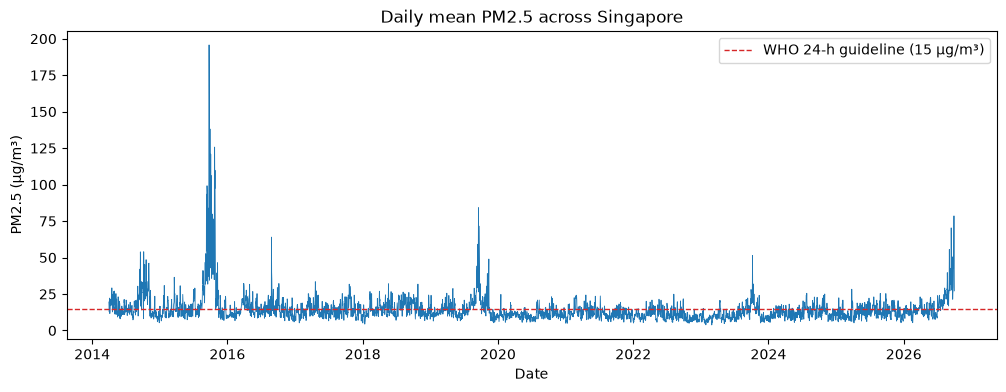

In [3]:
fig = eda.plot_daily_series(df)
eda.save_figure(fig, "01_daily_series")
plt.show()

In [4]:
# The worst days on record (average of all regions)
df[REGIONS].mean(axis=1).resample("D").mean().nlargest(5).round(0)

timestamp
2015-09-24    196.0
2015-09-25    158.0
2015-09-29    138.0
2015-10-24    126.0
2015-10-03    121.0
dtype: float64

**Observation:** the series is mostly flat around 10–20 µg/m³ with sharp
spikes. The largest are the **September–October 2015 transboundary haze**
(daily mean near 200 µg/m³), with smaller episodes in 2019, 2023 and
**August–September 2026**, right at the end of the data. 2020–2025 is
comparatively calm. Two consequences:
- These rare events matter most to the public but are the hardest to forecast,
  so the evaluation should look at them separately.
- A time-based test split (the most recent data) will contain the 2026 haze,
  so test errors may be higher than validation errors on calmer years.

## 3. Distribution of values

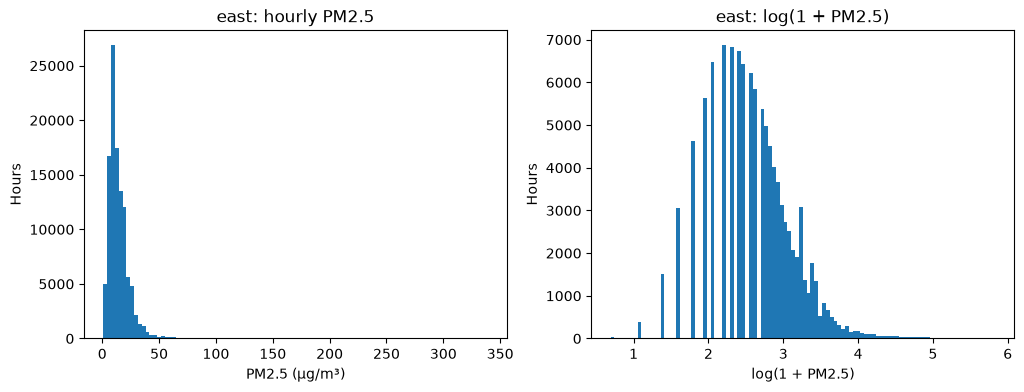

Skewness: 6.29


In [5]:
fig = eda.plot_distribution(df["east"])
eda.save_figure(fig, "02_distribution_east")
plt.show()
print("Skewness:", round(df["east"].skew(), 2))

**Observation:** the values are strongly right-skewed (skewness ≈ 6). After
`log(1 + x)` they look much more symmetric. Worth trying a log-transformed
target for linear models, and RMSE will be dominated by the haze hours.

## 4. Daily and seasonal patterns

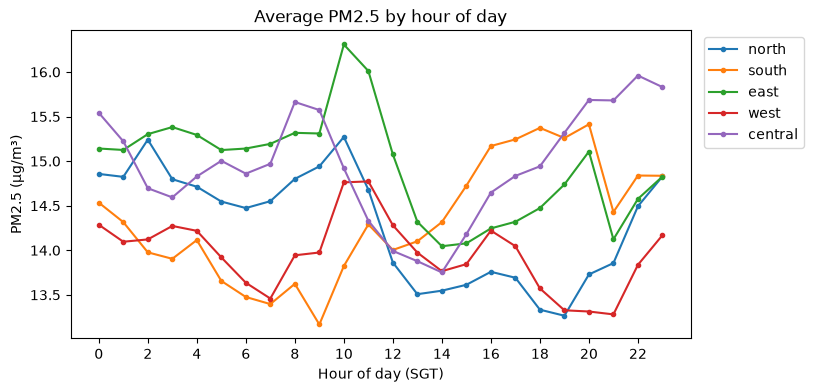

In [6]:
fig = eda.plot_hourly_profile(df)
eda.save_figure(fig, "03_hourly_profile")
plt.show()

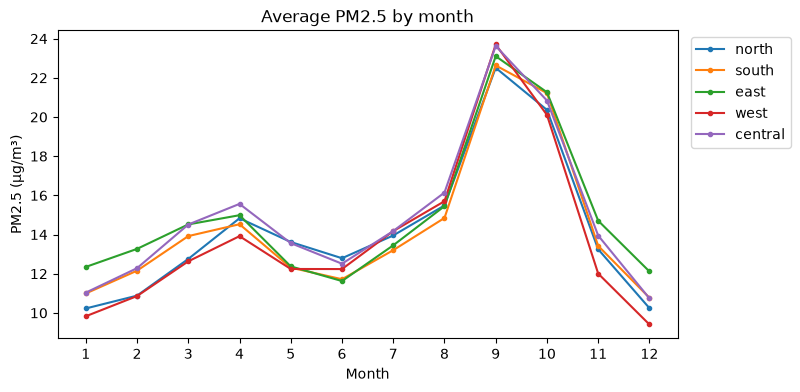

In [7]:
fig = eda.plot_monthly_profile(df)
eda.save_figure(fig, "04_monthly_profile")
plt.show()

**Observation:**
- **Hour of day:** a weak pattern (only about ±1.5 µg/m³, roughly 13–16),
  and it differs by region (e.g. East peaks around 10:00, Central in the late
  evening). Hour of day is a cheap feature but will not explain much.
- **Month:** a clear peak in **September–October** (the haze season, linked
  to regional fires during the southwest monsoon). Month (or day of year) is a
  useful feature.

## 5. How similar are the regions?

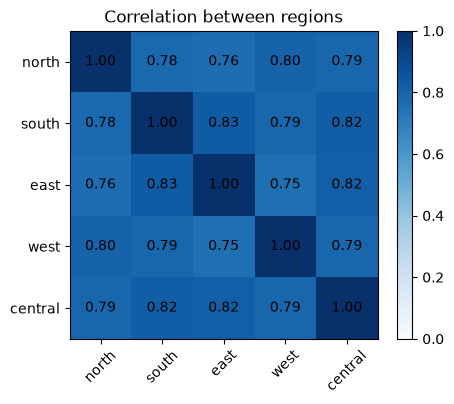

In [8]:
fig = eda.plot_region_correlation(df)
eda.save_figure(fig, "05_region_correlation")
plt.show()

**Observation:** the regions are strongly correlated (0.75–0.83), since
pollution such as haze covers the whole island. So the other regions' recent
values are likely helpful features for forecasting one region.

## 6. How far back should the model look?

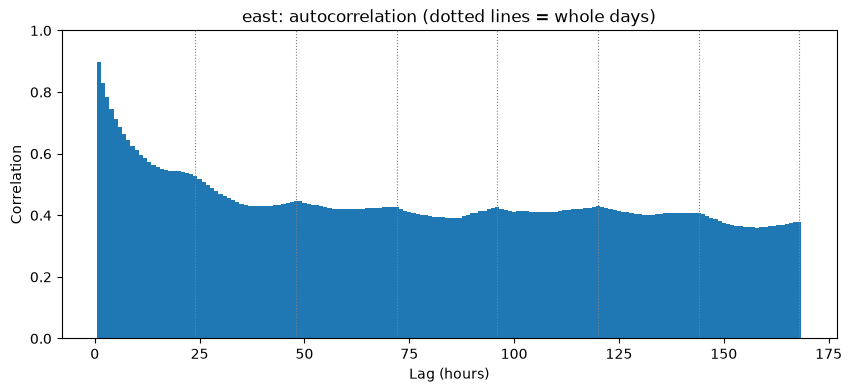

1     0.897
2     0.830
3     0.783
6     0.688
12    0.584
24    0.528
48    0.448
Name: autocorrelation, dtype: float64

In [9]:
fig = eda.plot_autocorrelation(df["east"], max_lag=168)
eda.save_figure(fig, "06_autocorrelation_east")
plt.show()
eda.autocorrelation(df["east"], 48)[[1, 2, 3, 6, 12, 24, 48]].round(3)

**Observation:** the value one hour ago is very informative (correlation ≈
0.90), dropping to ≈ 0.69 at 6 h and ≈ 0.53 at 24 h, with a small bump at each
whole day. This supports the planned **24–48 hour input window**: recent
hours carry most of the signal, and the 24-hour lag adds a little.

## 7. The baseline to beat

In [10]:
horizons = [1, 2, 3, 4, 5, 6]
baseline = eda.persistence_errors(df["east"], horizons)
baseline.round(2)

,RMSE,MAE
horizon_hours,,
1,5.44,3.77
2,6.99,4.70
3,7.89,5.25
4,8.56,5.64
5,9.07,5.93
6,9.47,6.18


The **persistence baseline** forecasts "PM2.5 in *h* hours = PM2.5 now".
Its error grows with the horizon (RMSE ≈ 5.4 at 1 h, ≈ 9.5 at 6 h for East).
Any model we build must beat these numbers on the same test period to be
worth using. (These are computed on the full series; the final comparison
will use only the test split.)

## 8. Summary: what this means for modelling

| Finding | Decision |
| --- | --- |
| Strong short-term autocorrelation | Use lagged values from the last 24–48 h as features |
| Regions move together | Include other regions' recent values |
| Haze season in Sep–Oct, weak daily cycle | Add month / hour-of-day features |
| Very skewed values, rare haze spikes | Try a log target; report errors on haze periods separately |
| Persistence RMSE 5.4 (1 h) to 9.5 (6 h) | This is the baseline every model must beat |
| Time series data | Split train / validation / test **by time**, never randomly |